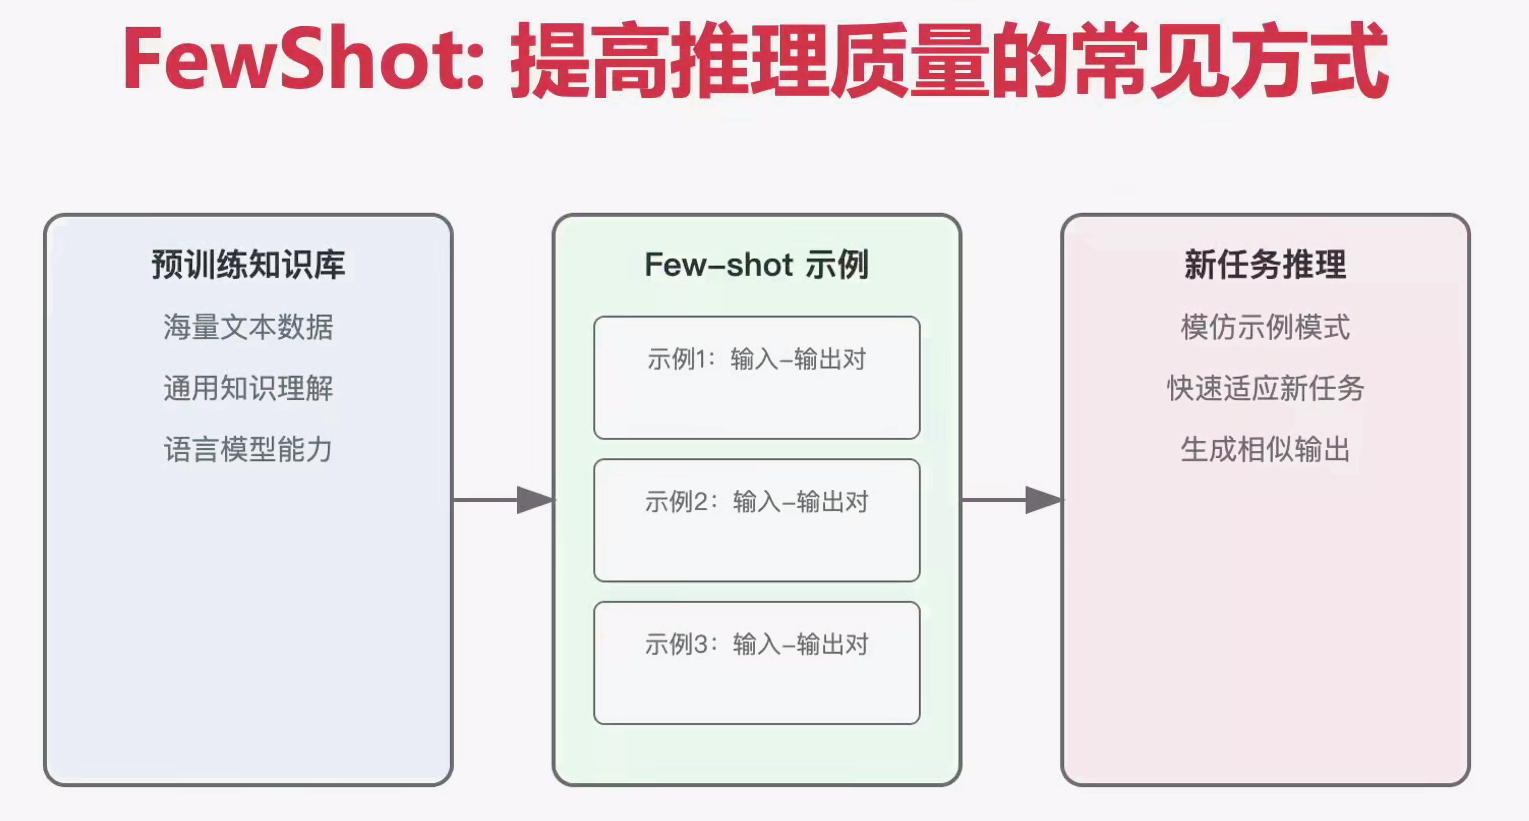

In [6]:
# zero shot会导致低质量回答
from langchain_openai import ChatOpenAI
import os
from dotenv import load_dotenv
load_dotenv()

model = ChatOpenAI(
    model="Qwen/Qwen3.8-27B",  # 模型名称          
    api_key=os.getenv("api_key"),  # 在环境变量中设置的API Key
    base_url=os.getenv("base_url"), # 在环境变量中设置的API请求地址
    temperature=0,
)

res = model.invoke("What is 2 🐦 9？")
print(res.content)



It’s not a standard math expression, so there’s no single answer without knowing what 🐦 means.

- If it’s just a bird: “2 birds and 9”
- If 🐦 means **+**: 2 + 9 = **11**
- If 🐦 means **×**: 2 × 9 = **18**
- If 🐦 means **^**: 2⁹ = **512**

Tell me what the bird is supposed to represent, and I can give the exact answer.


In [ ]:
# 增加示例
# 使用FewShotChatMessagePromptTemplate
from langchain_core.prompts import ChatPromptTemplate, FewShotChatMessagePromptTemplate

from langchain_openai import ChatOpenAI
import os
from dotenv import load_dotenv
load_dotenv()

model = ChatOpenAI(
    model="Qwen/Qwen3.8-27B",  # 模型名称          
    api_key=os.getenv("api_key"),  # 在环境变量中设置的API Key
    base_url=os.getenv("base_url"), # 在环境变量中设置的API请求地址
    temperature=0,
)

# 增加示例组
examples = [
    { "input": "2 🐦 2", "output": "4" },
    { "input": "2 🐦 3", "output": "5" },
]

# 构造提示词模板
example_prompt = ChatPromptTemplate.from_messages(
    [
        ("human", "{input}"),
        ("ai", "{output}"),
    ]
)

# 组合示例与提示词
few_shot_prompt = FewShotChatMessagePromptTemplate(
    example_prompt=example_prompt,
    examples=examples,
)

# 打印提示词模板
print("组合之后的提示词为=====>")
print(few_shot_prompt.invoke({}).to_messages())

# 最终提示词
final_prompt = ChatPromptTemplate.from_messages(
    [
        ("system", "你是一个神奇的数学天才"),
        few_shot_prompt,
        ("human", "{input}"),
    ]
)

# 重新提问
chain = final_prompt | model
result = chain.invoke({"input": "What is 2 🐦 9？"})
print("处理之后的答案为=====>")
print(result.content)

组合之后的提示词为=====>
[HumanMessage(content='2 🐦 2', additional_kwargs={}, response_metadata={}), AIMessage(content='4', additional_kwargs={}, response_metadata={}, tool_calls=[], invalid_tool_calls=[]), HumanMessage(content='2 🐦 3', additional_kwargs={}, response_metadata={}), AIMessage(content='5', additional_kwargs={}, response_metadata={}, tool_calls=[], invalid_tool_calls=[])]


11
